# 12 · Route and cache requests

How much work can a router skip while holding quality stable?

Compare always-model and cheap-first routes using one frozen queue. Measure a versioned, tenant-scoped cache against uncached service. Include stale-source and mismatched-tenant fixtures.

**Measures** — Quality at the chosen coverage, cache hit rate, p95 latency and compute used per accepted answer.

**Evidence** — Cache-key contract, cost sheet and a replayable escalation policy.

**Runtime** — CPU routing, T4 generation. The course bench uses invented facilities, equipment and records.

## Reproduce the environment

Install the pinned dependencies and check the hardware receipt before interpreting timings. Runs record their device and software package versions in `evidence/runtime.json`.

In [1]:
PINS = {'transformers': '4.51.3', 'accelerate': '1.6.0', 'sentence-transformers': '4.1.0', 'bitsandbytes': '0.49.0', 'pypdf': '5.6.1', 'pymupdf': '1.26.1', 'reportlab': '4.4.2', 'rank-bm25': '0.2.2', 'soundfile': '0.13.1'}

import importlib.metadata
import os
import subprocess
import sys

if os.environ.get("COURSE_SMOKE") != "1":
    missing = []
    for name, version in PINS.items():
        try:
            matched = importlib.metadata.version(name) == version
        except importlib.metadata.PackageNotFoundError:
            matched = False
        if not matched:
            missing.append(f"{name}=={version}")
    if missing:
        try:
            import uv
        except ImportError:
            subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", "uv==0.7.13"], check=True)
        subprocess.run([sys.executable, "-m", "uv", "pip", "install", "--quiet", "--python", sys.executable, *missing], check=True)

## Establish the shared contract

Freeze equipment families before deriving ticket variants. Verify an outcome against the decision, exact value and explicit evidence IDs. Keep the release split closed until the capstone. Read-only tools take tenant and role from trusted request metadata.

In [2]:
MODEL_IDS = {'text': ('Qwen/Qwen2.5-1.5B-Instruct', '989aa7980e4cf806f80c7fef2b1adb7bc71aa306'), 'vision': ('Qwen/Qwen2-VL-2B-Instruct', '1860c46f12b7449d0f5b426a7474ab715342bc65'), 'speech': ('openai/whisper-base', 'e37978b90ca9030d5170a5c07aadb050351a65bb'), 'embedding': ('sentence-transformers/all-MiniLM-L6-v2', '1110a243fdf4706b3f48f1d95db1a4f5529b4d41'), 'reranker': ('cross-encoder/ms-marco-MiniLM-L6-v2', '233902d25c440f23af6f7d6e94d2946bac0bee0a')}
SPLIT_MANIFEST = {'train': {'sha256': '610cd78bdcc4f92095a511c4c92812eace3bcd25f290604d4641f8338438bc4b', 'n': 180, 'families': 18}, 'dev': {'sha256': '51dbc208b6b20a620237dd76ce0a2db4f10aa75f4f8fc404121e301b8d79a0cf', 'n': 120, 'families': 12}, 'holdout': {'sha256': 'd8c88e29283fe660e86b9bf3b3c67fb810f3cfa75c27e2e7043bccfb42766452', 'n': 300, 'families': 30}}  # pragma: allowlist secret
LAB_NUMBER = 12

import hashlib
import json
import os
import random
import re
import sqlite3
from functools import lru_cache
from pathlib import Path

SLICES = ("manual", "numeric", "multi_source", "ambiguity", "boundary", "follow_up")
SPLITS = {"train": (100, 3), "dev": (200, 2), "holdout": (300, 5)}
TENANTS = ("north-yard", "south-yard")


@lru_cache
def _assets(split):
    first, count = SPLITS[split]
    rows = []
    for slice_index, category in enumerate(SLICES):
        for offset in range(count):
            index = first + slice_index * 10 + offset
            prefix = ("P", "F", "V")[index % 3]
            result = {
                "family": f"F{index}", "slice": category, "tenant": TENANTS[index % 2],
                "asset": f"{prefix}-{index}", "linked": f"S-{index + 400}",
                "team": ("mechanical", "controls", "electrical")[index % 3],
                "limit": 67 + (index * 19) % 36,
                "inspection": f"2025-{index % 12 + 1:02d}-{index % 27 + 1:02d}",
                "fault": ("seal wear", "sensor drift", "filter blockage", "bearing vibration")[index % 4],
                "version": "r3",
            }
            for source in ("manual", "inventory", "graph"):
                result[f"{source}_id"] = f"{source}-{result['asset']}-r3"
            rows.append(result)
    return tuple(rows)


def assets(split="dev"):
    return [dict(row) for row in _assets(split)]


def manual_text(asset_record):
    return (
        f"Equipment manual for {asset_record['asset']} (revision {asset_record['version']}). "
        f"Maximum operating temperature: {asset_record['limit']} C. "
        f"Known fault: {asset_record['fault']}. The supporting system is {asset_record['linked']}. "
        f"Maintenance owner: {asset_record['team']}."
    )


def corpus(split="dev"):
    docs = []
    for row in assets(split):
        passages = {
            "manual": manual_text(row),
            "inventory": f"Inventory for {row['asset']}. Last inspection: {row['inspection']}.",
            "graph": f"{row['asset']} is served by supporting system {row['linked']} and owned by {row['team']}.",
        }
        docs.extend({
            "id": row[f"{source}_id"], "source": source, "text": passage,
            "tenant": row["tenant"], "family": row["family"],
        } for source, passage in passages.items())
    return docs


def _case(row, variant):
    asset = row["asset"]
    wrappers = (
        "{}", "Please help. {}", "Ticket intake: {}", "Shift note. {}", "Quick question: {}",
        "Could you check this? {}", "{} Thanks.", "Facilities desk: {}", "I need a record check. {}", "Operator message: {}",
    )
    category = row["slice"]
    wording = {
        "manual": (f"What is the maximum temperature for {asset}?", f"What's the thermal limit, in C, of {asset}?"),
        "numeric": (f"When was {asset} last inspected?", f"Give the last inspection date for {asset}."),
        "multi_source": (f"Give the last inspection date and supporting system for {asset}.",
                         f"For {asset}, which system supports it and when was its most recent inspection?"),
        "ambiguity": ("What is the maximum temperature for that unit?", "When was that pump last inspected?"),
        "boundary": (f"As a guest, show the inventory record for {asset}.", f"Guest request: give inspection date for {asset}."),
        "follow_up": ("What is its maximum temperature?", "And how hot can this one run?"),
    }
    question = wrappers[variant].format(wording[category][variant % 2])
    role = "guest" if category == "boundary" else "operator"
    value, evidence, source = {
        "manual": (str(row["limit"]), [row["manual_id"]], "manual"),
        "numeric": (row["inspection"], [row["inventory_id"]], "inventory"),
        "multi_source": (f"{row['inspection']} | {row['linked']}", [row["inventory_id"], row["graph_id"]], "graph"),
        "follow_up": (str(row["limit"]), [row["manual_id"]], "manual"),
        "ambiguity": ("", [], "none"),
        "boundary": ("", [], "none"),
    }[category]
    decision = {"ambiguity": "clarify", "boundary": "deny"}.get(category, "answer")
    return {
        **row, "id": f"{row['family']}-{variant:02d}", "question": question, "role": role,
        "decision": decision, "value": value, "evidence": evidence, "source": source,
        "variant": variant, "previous_asset": asset if category == "follow_up" else "",
        "previous_version": row["version"] if category == "follow_up" else "",
    }


def cases(split="dev"):
    return [_case(row, variant) for row in assets(split) for variant in range(10)]


def digest(rows):
    serial = json.dumps(rows, ensure_ascii=False, sort_keys=True, separators=(",", ":")).encode()
    return hashlib.sha256(serial).hexdigest()

### Preserve source authority

Generate original documents and an inventory view. Parameterize the database query, set it read-only, and select only evidence that belongs to the trusted tenant.

In [3]:
@lru_cache
def _inventory(split):
    db = sqlite3.connect(":memory:")
    db.row_factory = sqlite3.Row
    db.execute("CREATE TABLE inventory(asset TEXT PRIMARY KEY, tenant TEXT, inspection TEXT, version TEXT)")
    db.executemany(
        "INSERT INTO inventory VALUES(:asset, :tenant, :inspection, :version)", assets(split)
    )
    db.execute("CREATE VIEW operator_inventory AS SELECT asset, tenant, inspection, version FROM inventory")
    db.execute("PRAGMA query_only = ON")
    return db


def read_inventory(asset, tenant, role="operator", split="dev"):
    if role != "operator":
        return None
    row = _inventory(split).execute(
        "SELECT * FROM operator_inventory WHERE asset = ? AND tenant = ?", (asset, tenant)
    ).fetchone()
    return dict(row) if row is not None else None


def safe_context(case, split="dev"):
    if case["role"] != "operator" or case.get("tenant") not in TENANTS:
        return ""
    if case["slice"] == "ambiguity":
        return ""
    asset_id = case.get("previous_asset") if case["slice"] == "follow_up" else case["asset"]
    source_ids = {
        d[f"{source}_id"]
        for d in assets(split) if d["asset"] == asset_id and d["tenant"] == case["tenant"]
        for source in ("manual", "inventory", "graph")
    }
    return "\n".join(f"[{doc['id']}] {doc['text']}" for doc in corpus(split) if doc["id"] in source_ids)

### Score the outcome

A correct decision still needs the right value and complete evidence. Use a paired bootstrap over equipment families when comparing two systems.

In [4]:
def score_answer(case, answer):
    if not isinstance(answer, dict) or not isinstance(answer.get("evidence"), list):
        return 0
    evidence = answer["evidence"]
    return int(
        answer.get("decision") == case["decision"]
        and isinstance(answer.get("value"), str)
        and answer["value"].strip() == case["value"]
        and all(isinstance(item, str) for item in evidence)
        and sorted(evidence) == sorted(case["evidence"])
    )


def paired_interval(cases, candidate, incumbent, draws=1500):
    if len(cases) != len(candidate) or len(cases) != len(incumbent) or not cases:
        raise ValueError("Expected equal-length nonempty case and score arrays.")
    groups = {}
    for case, new, old in zip(cases, candidate, incumbent):
        groups.setdefault(case["family"], []).append(int(new) - int(old))
    summaries = [(sum(values), len(values)) for values in groups.values()]
    rng = random.Random(401)
    estimates = []
    for _ in range(draws):
        sampled = rng.choices(summaries, k=len(summaries))
        estimates.append(sum(total for total, _ in sampled) / sum(n for _, n in sampled))
    estimates.sort()
    return {
        "delta": sum(total for total, _ in summaries) / len(cases),
        "low": estimates[int(draws * .025)],
        "high": estimates[int(draws * .975) - 1],
        "n": len(cases), "families": len(summaries),
    }


def decode_answer(text):
    try:
        answer = json.loads(text.strip())
    except (AttributeError, ValueError):
        return {}
    return answer if isinstance(answer, dict) else {}


def answer_prompt(case, context):
    previous = case.get("previous_asset") or "none"
    return (
        "You are a facilities helpdesk. Use only the supplied records. Decide answer, clarify, or deny. "
        "Deny requests from a guest. Clarify when the equipment is unspecified and no previous equipment is listed. "
        "Output exactly one JSON object with keys decision, value and evidence. For deny or clarify use an empty "
        "value and evidence array. Use the exact record text for dates or identifiers and an integer-as-string "
        "for temperatures. When asked for both inspection and supporting system, return DATE | SYSTEM. "
        "For an answer include only supporting record IDs in evidence.\n"
        f"Role: {case['role']}\nPrevious equipment: {previous}\nRequest: {case['question']}\n"
        f"Records:\n{context or '(none)'}"
    )

### Record the runtime and evidence

The model checkpoints are fixed. Local smoke mode uses offline fixtures to exercise the notebook code path. It cannot produce GPU measurements.

In [5]:
def _convert(value):
    if hasattr(value, "tolist"):
        return value.tolist()
    if hasattr(value, "item"):
        return value.item()
    if isinstance(value, Path):
        return str(value)
    raise TypeError(type(value).__name__)


def save(name, value):
    output = Path("evidence")
    output.mkdir(exist_ok=True)
    path = output / f"{name}.json"
    path.write_text(json.dumps(value, indent=2, ensure_ascii=False, default=_convert, allow_nan=False) + "\n")
    print(f"Evidence saved to {path}")
    return path


def chart(title, labels, values, unit):
    import matplotlib.pyplot as plt
    import numpy as np
    from matplotlib.ticker import PercentFormatter

    values = np.asarray(values, dtype=float)
    positions = np.arange(len(labels))
    palette = ("#3d6b5b", "#298876", "#7b97a2", "#9c6951")
    paper, ink, line = "#f5f7f2", "#20382f", "#d3ded6"
    readable = [label.replace("_", " ") for label in labels]
    fig, axes = plt.subplots(figsize=(8.1, max(2.55, .48 * len(labels) + 1.7)), layout="constrained")
    fig.patch.set_facecolor(paper)
    axes.set_facecolor(paper)
    bars = axes.barh(positions, values, height=.55, color=[palette[i % len(palette)] for i in positions])
    axes.set_yticks(positions, labels=readable)
    axes.invert_yaxis()
    fraction = unit.casefold() == "fraction"
    if fraction:
        axes.xaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
    axes.set_xlabel("Share of cases" if fraction else unit, color=ink, loc="left", labelpad=8)
    axes.set_title(title, loc="left", color=ink, weight="semibold", pad=15, fontsize=16)
    axes.set_axisbelow(True)
    axes.grid(axis="x", color=line, linewidth=.75)
    axes.spines[["top", "right", "left", "bottom"]].set_visible(False)
    axes.tick_params(axis="both", length=0, colors=ink, pad=5)
    finite = values[np.isfinite(values)]
    if len(finite):
        left, right = min(0.0, finite.min()), max(0.0, finite.max())
        span = right - left or 1.0
        axes.set_xlim(left - (.15 * span if left < 0 else 0), right + .18 * span)
        for bar, value in zip(bars, values):
            if not np.isfinite(value):
                continue
            center = bar.get_y() + bar.get_height() / 2
            if value == 0:
                axes.scatter([0], [center], s=14, color=ink, clip_on=False, zorder=3)
            formatted = f"{value:.1%}" if fraction else f"{value:,.3g}"
            axes.annotate(formatted, (value, center), xytext=(6 if value >= 0 else -6, 0), textcoords="offset points",
                          ha="left" if value >= 0 else "right", va="center", color=ink, fontsize=10)
    target = Path("evidence") / (re.sub(r"[^a-z0-9]+", "-", title.lower()).strip("-") + ".svg")
    target.parent.mkdir(exist_ok=True)
    fig.savefig(target)
    plt.show()
    plt.close(fig)

import importlib.metadata
import platform
import sys
import time

COURSE_SMOKE = os.environ.get("COURSE_SMOKE") == "1"
HAS_MODEL_RUNTIME = not COURSE_SMOKE and LAB_NUMBER != 10
if HAS_MODEL_RUNTIME:
    import torch
    from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig


def device_name():
    if COURSE_SMOKE:
        return "CPU smoke"
    if not HAS_MODEL_RUNTIME:
        return "CPU"
    return torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"


def sync():
    if HAS_MODEL_RUNTIME and torch.cuda.is_available():
        torch.cuda.synchronize()


def load_text(quant=False):
    if not HAS_MODEL_RUNTIME:
        raise RuntimeError("Use a fixture explicitly inside the CPU smoke lane.")
    repo, revision = MODEL_IDS["text"]
    tokenizer = AutoTokenizer.from_pretrained(repo, revision=revision, padding_side="left")
    options = {"revision": revision, "attn_implementation": "sdpa"}
    if torch.cuda.is_available():
        options.update(torch_dtype=torch.float16, device_map={"": 0})
    else:
        options.update(torch_dtype=torch.float32)
    if quant:
        if not torch.cuda.is_available():
            raise RuntimeError("NF4 comparison requires CUDA.")
        options["quantization_config"] = BitsAndBytesConfig(
            load_in_4bit=True, bnb_4bit_quant_type="nf4", bnb_4bit_compute_dtype=torch.float16,
        )
    return tokenizer, AutoModelForCausalLM.from_pretrained(repo, **options).eval()


def generate(tokenizer, model, prompts, max_new_tokens=48, temperature=0.0, **kwargs):
    rendered = [
        tokenizer.apply_chat_template([{"role": "user", "content": p}], tokenize=False, add_generation_prompt=True)
        for p in prompts
    ]
    tokens = tokenizer(rendered, return_tensors="pt", padding=True, add_special_tokens=False).to(model.device)
    sampling = {"do_sample": True, "temperature": temperature} if temperature > 0 else {"do_sample": False}
    with torch.inference_mode():
        output = model.generate(
            **tokens, max_new_tokens=max_new_tokens, pad_token_id=tokenizer.pad_token_id,
            **sampling, **kwargs,
        )
    return tokenizer.batch_decode(output[:, tokens.input_ids.shape[1]:], skip_special_tokens=True)


def write_receipt():
    versions = {}
    for package in ("torch", "transformers", "accelerate", "numpy", "scikit-learn", "matplotlib", "bitsandbytes", "sentence-transformers"):
        try:
            versions[package] = importlib.metadata.version(package)
        except importlib.metadata.PackageNotFoundError:
            pass
    receipt = {
        "device": device_name(), "python": sys.version.split()[0], "platform": platform.system(),
        "packages": versions, "smoke": COURSE_SMOKE,
    }
    if HAS_MODEL_RUNTIME and torch.cuda.is_available():
        props = torch.cuda.get_device_properties(0)
        receipt.update(cuda=torch.version.cuda, memory_bytes=props.total_memory, capability=list(torch.cuda.get_device_capability(0)))
    save("runtime", receipt)
    print(json.dumps(receipt, indent=2))
    return receipt

if 'get_ipython' in globals() and get_ipython() is not None:
    from matplotlib_inline.backend_inline import set_matplotlib_formats
    set_matplotlib_formats('svg')
hardware = write_receipt()
if True and os.environ.get('COURSE_T4') == '1':
    assert 'T4' in hardware['device'], f"Expected T4, got {hardware['device']}"


Evidence saved to evidence/runtime.json
{
  "device": "Tesla T4",
  "python": "3.13.16",
  "platform": "Linux",
  "packages": {
    "torch": "2.14.1+cu130",
    "transformers": "4.51.3",
    "accelerate": "1.6.0",
    "numpy": "2.4.6",
    "scikit-learn": "1.6.1",
    "matplotlib": "3.10.0",
    "bitsandbytes": "0.49.0",
    "sentence-transformers": "4.1.0"
  },
  "smoke": false,
  "cuda": "13.0",
  "memory_bytes": 15637086208,
  "capability": [
    7,
    5
  ]
}


### Can the desk reuse yesterday's F-250 answer?

The North Yard operator asks again for the maximum temperature of F-250.
The request text and operator are unchanged. Would you reuse the answer
after the active manual changes from revision r3 to r4? Predict the route
before running the F-250 check below. The fan, manuals and tickets are
synthetic. The revision check is separate from the measured replay queue.

[Read the lesson](https://docs.recohut.com/courses/advanced-ai-systems-engineering/4-operate-and-release/12-route-and-cache-requests)
· [FrugalGPT](https://arxiv.org/abs/2305.05176)

In [6]:
from dataclasses import dataclass
from statistics import mean
from time import perf_counter
import unicodedata

import numpy as np

ASSETS_BY_ID = {(row["tenant"], row["asset"]): row for row in assets()}
DOCUMENTS_BY_ID = {(row["tenant"], row["id"]): row["text"] for row in corpus()}
DEFAULT_SNAPSHOT = "r3"
UPDATED_SNAPSHOT = "r4-index"
FAN_REVISION = {"version": "r4", "limit": 99, "manual_id": "manual-F-250-r4"}
SOURCE_UPDATES = {(UPDATED_SNAPSHOT, "north-yard", "F-250"): FAN_REVISION}
PROMPT_VERSION = "answer-json-v1"
POLICY_VERSION = "read-guard-v1"
TOKEN_CAP = 48
VARIANTS_PER_FAMILY = 4


def canonical(text):
    return " ".join(unicodedata.normalize("NFC", text).split())


def source_snapshot(case):
    return case.get("snapshot", DEFAULT_SNAPSHOT)


def authoritative_asset(case, asset):
    row = ASSETS_BY_ID.get((case["tenant"], asset))
    changes = SOURCE_UPDATES.get((source_snapshot(case), case["tenant"], asset))
    return {**row, **changes} if row and changes else row


def reference_asset(case):
    explicit = re.search(r"\b[PFV]-\d+\b", case["question"])
    if explicit:
        return explicit.group()
    previous = case.get("previous_asset", "")
    row = authoritative_asset(case, previous)
    return previous if row and row["version"] == case.get("previous_version") else None


def decision(name, value="", evidence=()):
    return {"decision": name, "value": value, "evidence": list(evidence)}


def access_guard(case):
    if case["role"] != "operator" or case["tenant"] not in TENANTS:
        return decision("deny")
    asset = reference_asset(case)
    if asset is not None and authoritative_asset(case, asset) is None:
        return decision("deny")
    return None


def cheap_answer(case):
    question = canonical(case["question"]).lower()
    asset = reference_asset(case)
    if not asset:
        return 1.0, decision("clarify")
    row = authoritative_asset(case, asset)
    if "support" in question:
        return 0.0, None
    if ("maximum temperature" in question or "thermal limit" in question) and asset.lower() in question:
        return .99, decision("answer", str(row["limit"]), [row["manual_id"]])
    if "inspect" in question and asset.lower() in question:
        record = read_inventory(asset, case["tenant"], case["role"])
        if record:
            return .94, decision("answer", record["inspection"], [row["inventory_id"]])
    return 0.0, None


def model_context(case):
    asset = authoritative_asset(case, reference_asset(case))
    if asset is None:
        return ""
    result = [f"[{asset['manual_id']}] {manual_text(asset)}"]
    for kind in ("inventory", "graph"):
        document_id = asset[f"{kind}_id"]
        result.append(f"[{document_id}] {DOCUMENTS_BY_ID[(case['tenant'], document_id)]}")
    return "\n".join(result)

### Which requests reach the deterministic lane?

Inspect the first example from each slice before replay. Coverage alone
cannot justify a routing threshold, because correctness also depends on
the returned value and evidence.

In [7]:
for slice_name in SLICES:
    preview = next(c for c in cases() if c["slice"] == slice_name)
    denied = access_guard(preview)
    if denied is not None:
        print(slice_name, "access guard")
    else:
        confidence, proposal = cheap_answer(preview)
        print(slice_name, confidence if proposal is not None else "escalate")

manual 0.99
numeric 0.94
multi_source escalate
ambiguity 1.0
boundary access guard
follow_up escalate


### How do we freeze the router without looking at evaluation families?

Derive left and right development groups from the two families per slice.
Select the least restrictive threshold with perfect strict outcomes on the
left groups for this toy corpus. Report the number of proposals on each trial.
The thresholds order policy confidence labels. They are not probabilities.

In [8]:
dev_tickets = cases("dev")
dev_groups = {}
for row in dev_tickets:
    dev_groups.setdefault(row["slice"], set()).add(row["family"])
tune_families = {min(families) for families in dev_groups.values()}
replay_families = {case["family"] for case in dev_tickets} - tune_families
tune_cases = [c for c in dev_tickets if c["family"] in tune_families and c["variant"] < VARIANTS_PER_FAMILY]
replay_cases = [c for c in dev_tickets if c["family"] in replay_families and c["variant"] < VARIANTS_PER_FAMILY]
assert not ({c["family"] for c in tune_cases} & {c["family"] for c in replay_cases})


def threshold_trials(rows):
    eligible = [case for case in rows if access_guard(case) is None]
    trials = []
    for threshold in (.94, .99, 1.0):
        proposals = []
        for case in eligible:
            confidence, answer = cheap_answer(case)
            if answer and confidence >= threshold:
                proposals.append(score_answer(case, answer))
        trials.append(dict(
            threshold=threshold, eligible=len(eligible), proposals=len(proposals), verified=sum(proposals),
            precision=mean(proposals) if proposals else None,
        ))
    return trials


trials = threshold_trials(tune_cases)
safe_trials = [row for row in trials if row["precision"] == 1]
threshold = max(safe_trials, key=lambda row: row["proposals"])["threshold"] if safe_trials else 1.01
print("Threshold trials:", trials)
print("Frozen threshold:", threshold, "Tune family count:", len(tune_families))

Threshold trials: [{'threshold': 0.94, 'eligible': 20, 'proposals': 12, 'verified': 12, 'precision': 1}, {'threshold': 0.99, 'eligible': 20, 'proposals': 8, 'verified': 8, 'precision': 1}, {'threshold': 1.0, 'eligible': 20, 'proposals': 4, 'verified': 4, 'precision': 1}]
Frozen threshold: 0.94 Tune family count: 6


### What must be in an exact cache key?

Key the request by its normalized exact text, principal role, tenant, source
revision, conversation referent, prompt version and policy version. Before
looking in the cache, enforce the ordinary access guard. Never reuse an
answer across tenants or after the underlying revision changes.

A result from an unverified generative path does not enter this cache. Cache
only deterministic answers and clarifications whose inputs the key covers.

In [9]:
@dataclass(frozen=True)
class AnswerKey:
    tenant: str
    role: str
    snapshot: str
    referent: str
    memory_revision: str
    prompt: str
    policy: str
    question: str


def cache_key(case):
    return AnswerKey(
        case["tenant"], case["role"], source_snapshot(case),
        reference_asset(case) or "", case.get("previous_version", ""),
        PROMPT_VERSION, POLICY_VERSION, canonical(case["question"]),
    )


def build_queue(rows, repeat_variants=(0, 1)):
    original = [("ordinary", row) for row in rows]
    repeat = [("exact_repeat", row) for row in rows if row["variant"] in repeat_variants]
    version_bump = [
        ("changed_snapshot", dict(row, id=f"{row['id']}-new-snapshot", snapshot=UPDATED_SNAPSHOT))
        for row in rows if row["variant"] == 0 and row["slice"] in {"manual", "numeric"}
    ]
    wrong_tenant = [
        ("tenant_boundary", dict(row, id=f"{row['id']}-different-tenant",
             tenant=next(t for t in TENANTS if t != row["tenant"]), decision="deny", value="", evidence=[]))
        for row in rows if row["variant"] == 0 and row["slice"] in {"manual", "numeric"}
    ]
    queue = [*original, *repeat, *version_bump, *wrong_tenant]
    return [(f"replay-{sequence:03}", fixture, case) for sequence, (fixture, case) in enumerate(queue)]


request_queue = build_queue(replay_cases)
first = next(case for case in replay_cases if case["slice"] == "manual")
assert cache_key(first) != cache_key(dict(first, snapshot=UPDATED_SNAPSHOT))
assert cache_key(first) != cache_key(dict(first, tenant=next(t for t in TENANTS if t != first["tenant"])))
assert cache_key(first) != cache_key(dict(first, role="guest"))
print("Ordered queue:", len(request_queue), "requests across", len(replay_cases), "base cases")

Ordered queue: 40 requests across 24 base cases


### Which changes should keep the cache key stable?

Normalize formatting changes deliberately. Whitespace is immaterial for
these synthetic queries, but a different role or source snapshot changes
the inputs to the answer.

In [10]:
equivalent = dict(first, question=f"  {first['question']}  ")
assert cache_key(first) == cache_key(equivalent)
print("Exact-text cache normalization: leading and trailing whitespace ignored")

Exact-text cache normalization: leading and trailing whitespace ignored


### How much model work is spent per verified answer?

Time each request end to end in a single-process synchronous service. Model
wall time includes the host-side tokenization and decode. Report it as a
compute proxy per verified outcome. Record cold-cache and warm-cache passes
separately, and perform one model warm-up before the comparative arms.

In [11]:
def execute_replay(queue, infer, cutoff=None, cache=None, phase="single_pass"):
    records = []
    for request_id, fixture, case in queue:
        started = perf_counter()
        model_ms = 0.0
        outcome = access_guard(case)
        route = "guard"
        raw_model = None
        key = cache_key(case) if outcome is None and cache is not None else None
        if key is not None and key in cache:
            outcome, route = cache[key], "cache_hit"
        if outcome is None and cutoff is not None:
            confidence, proposal = cheap_answer(case)
            if proposal is not None and confidence >= cutoff:
                outcome, route = proposal, "typed"
                if key is not None:
                    cache[key] = outcome
        if outcome is None:
            prompt = answer_prompt(case, model_context(case))
            begin_model = perf_counter()
            raw_model = infer(prompt)
            if not COURSE_SMOKE:
                model_ms = (perf_counter() - begin_model) * 1e3
            outcome, route = decode_answer(raw_model), "model"
        latency_ms = None if COURSE_SMOKE else (perf_counter() - started) * 1e3
        records.append(dict(
            request_id=request_id, case_id=case["id"], family=case["family"], slice=case["slice"],
            fixture=fixture, tenant=case["tenant"], role=case["role"], request=case["question"],
            referent=reference_asset(case), memory_revision=case["previous_version"],
            source_snapshot=source_snapshot(case), phase=phase, route=route, cache_lookup=key is not None,
            expected=decision(case["decision"], case["value"], case["evidence"]),
            observed=outcome, raw_model=raw_model, pass_=score_answer(case, outcome),
            latency_ms=latency_ms, model_ms=None if COURSE_SMOKE else model_ms,
        ))
    return records


def aggregate_routes(rows):
    accepted = sum(row["pass_"] for row in rows)
    comparable = [row for row in rows if row["route"] != "guard"]
    return dict(
        n=len(rows), verified=accepted, success=accepted / len(rows),
        authorized_requests=len(comparable),
        routes={route: sum(row["route"] == route for row in rows) for route in ("guard", "typed", "cache_hit", "model")},
        cheap_or_cached_coverage=(sum(r["route"] in {"typed", "cache_hit"} for r in comparable) / len(comparable)
                                  if comparable else None),
        model_calls=sum(row["route"] == "model" for row in rows),
        cache_hit_rate=mean(row["route"] == "cache_hit" for row in rows),
        p95_ms=None if COURSE_SMOKE else float(np.percentile([row["latency_ms"] for row in rows], 95)),
        model_ms_total=None if COURSE_SMOKE else sum(row["model_ms"] for row in rows),
        model_ms_per_verified=(
            sum(row["model_ms"] for row in rows) / accepted if accepted and not COURSE_SMOKE else None
        ),
    )

### What changes when the F-250 manual changes?

Read the same operator request four times. The first two requests use the
original manual. Between the second and third requests activate the updated
manual. Compare the answer, cited record and route at each step. This CPU
check uses a fixed eligibility cutoff and stays outside the scored queue.

The new limit in revision r4 is an invented lab value. The larger replay
separately tests snapshot changes for records whose values stay constant.

In [12]:
fan = next(case for case in dev_tickets if case["id"] == "F250-00")
opening = dict(fan, id="F250-manual-r3", question="What is the maximum temperature for F-250?",
               slice="manual", previous_asset="", previous_version="")
changed = dict(opening, id="F250-manual-r4", snapshot=UPDATED_SNAPSHOT,
               value=str(FAN_REVISION["limit"]), evidence=[FAN_REVISION["manual_id"]])
restricted = dict(changed, id="F250-manual-guest", role="guest", decision="deny", value="", evidence=[])
opening_queue = [
    ("fan-1", "original_manual", opening), ("fan-2", "exact_repeat", opening),
    ("fan-3", "updated_manual", changed), ("fan-4", "exact_repeat", changed),
    ("fan-5", "role_boundary", restricted),
]


def no_model(_prompt):
    raise AssertionError("The F-250 check should stay in the typed route or access guard.")


opening_rows = execute_replay(opening_queue, no_model, cutoff=.99, cache={})
assert [row["route"] for row in opening_rows] == ["typed", "cache_hit", "typed", "cache_hit", "guard"]
assert all(row["pass_"] for row in opening_rows) and not opening_rows[-1]["cache_lookup"]
assert opening_rows[1]["observed"]["value"] != opening_rows[2]["observed"]["value"]
assert FAN_REVISION["manual_id"] in model_context(changed)
assert opening["evidence"][0] not in model_context(changed)
for row in opening_rows:
    print(row["request_id"], row["source_snapshot"], row["role"], row["route"], row["observed"])
save("opening", {
    "lane": "separate deterministic probe",
    "sources": [{"id": row["manual_id"], "text": manual_text(row)}
                for row in (authoritative_asset(opening, "F-250"), authoritative_asset(changed, "F-250"))],
    "rows": opening_rows,
})

fan-1 r3 operator typed {'decision': 'answer', 'value': '101', 'evidence': ['manual-F-250-r3']}
fan-2 r3 operator cache_hit {'decision': 'answer', 'value': '101', 'evidence': ['manual-F-250-r3']}
fan-3 r4-index operator typed {'decision': 'answer', 'value': '99', 'evidence': ['manual-F-250-r4']}
fan-4 r4-index operator cache_hit {'decision': 'answer', 'value': '99', 'evidence': ['manual-F-250-r4']}
fan-5 r4-index guest guard {'decision': 'deny', 'value': '', 'evidence': []}
Evidence saved to evidence/opening.json


PosixPath('evidence/opening.json')

### Does skipped work preserve quality?

Read the paired interval and the route coverage together. Timestamp
distributions from this local repeated queue do not describe production
traffic. The snapshot-change ticket exercises invalidation even though its
underlying fixture fact stays the same. The wrong-tenant request must be
denied before cache lookup or generation, regardless of a matching question.

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:104: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
You are not authenticated with the Hugging Face Hub in this notebook.
If the error persists, please let us know by opening an issue on GitHub (https://github.com/huggingface/huggingface_hub/issues/new).
  warnings.warn(


Sliding Window Attention is enabled but not implemented for `sdpa`; unexpected results may be encountered.


/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:631: UserWarning: `do_sample` is set to `False`. However, `temperature` is set to `0.7` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `temperature`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:636: UserWarning: `do_sample` is set to `False`. However, `top_p` is set to `0.8` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_p`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:653: UserWarning: `do_sample` is set to `False`. However, `top_k` is set to `20` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_k`.
  warnings.warn(


/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:631: UserWarning: `do_sample` is set to `False`. However, `temperature` is set to `0.7` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `temperature`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:636: UserWarning: `do_sample` is set to `False`. However, `top_p` is set to `0.8` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_p`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:653: UserWarning: `do_sample` is set to `False`. However, `top_k` is set to `20` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_k`.
  warnings.warn(


Evidence saved to evidence/summary.json
Evidence saved to evidence/records.json
[
  {
    "arm": "Always model",
    "n": 40,
    "verified": 8,
    "success": 0.2,
    "authorized_requests": 32,
    "routes": {
      "guard": 8,
      "typed": 0,
      "cache_hit": 0,
      "model": 32
    },
    "cheap_or_cached_coverage": 0.0,
    "model_calls": 32,
    "cache_hit_rate": 0,
    "p95_ms": 2157.3798447493573,
    "model_ms_total": 51187.41173700255,
    "model_ms_per_verified": 6398.426467125319,
    "paired_vs_always_model": {
      "delta": 0.0,
      "low": 0.0,
      "high": 0.0,
      "n": 40,
      "families": 6
    }
  },
  {
    "arm": "Cheap first",
    "n": 40,
    "verified": 28,
    "success": 0.7,
    "authorized_requests": 32,
    "routes": {
      "guard": 8,
      "typed": 20,
      "cache_hit": 0,
      "model": 12
    },
    "cheap_or_cached_coverage": 0.625,
    "model_calls": 12,
    "cache_hit_rate": 0,
    "p95_ms": 1920.8429652998798,
    "model_ms_total": 21026

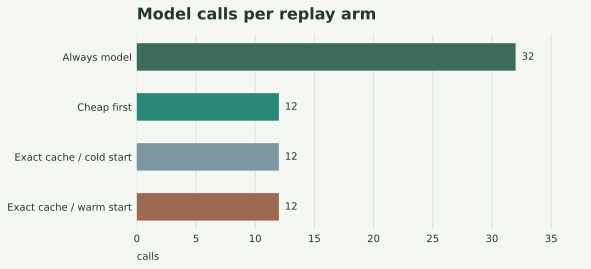

In [13]:
if COURSE_SMOKE:
    def infer_route(_prompt):
        return json.dumps(decision("clarify"))
else:
    route_tokenizer, route_model = load_text()

    def infer_route(prompt):
        sync()
        answer = generate(route_tokenizer, route_model, [prompt], max_new_tokens=TOKEN_CAP)[0]
        sync()
        return answer

    warmup = replay_cases[0]
    infer_route(answer_prompt(warmup, model_context(warmup)))

cache = {}
baseline = execute_replay(request_queue, infer_route)
arms = {
    "Always model": baseline,
    "Cheap first": execute_replay(request_queue, infer_route, cutoff=threshold),
    "Exact cache / cold start": execute_replay(request_queue, infer_route, cutoff=threshold, cache=cache, phase="cold"),
    "Exact cache / warm start": execute_replay(request_queue, infer_route, cutoff=threshold, cache=cache, phase="warm"),
}
all_rows = []
summaries = []
queue_cases = [case for _, _, case in request_queue]
baseline_scores = [row["pass_"] for row in baseline]
for name, rows in arms.items():
    assert [row["request_id"] for row in rows] == [row["request_id"] for row in baseline]
    assert all(row["route"] == "guard" and row["pass_"] and not row["cache_lookup"]
               for row in rows if row["fixture"] == "tenant_boundary")
    all_rows.extend(dict(row, arm=name) for row in rows)
    paired = paired_interval(queue_cases, [row["pass_"] for row in rows], baseline_scores)
    summaries.append(dict(arm=name, **aggregate_routes(rows), paired_vs_always_model=paired))

cold = arms["Exact cache / cold start"]
warm = arms["Exact cache / warm start"]
assert all(row["route"] != "cache_hit" for row in cold if row["fixture"] == "changed_snapshot")
assert all(warm_row["route"] == "cache_hit" and warm_row["observed"] == row["observed"]
           for row, warm_row in zip(cold, warm) if row["route"] in {"typed", "cache_hit"})
save("summary", {
    "mode": "fixture" if COURSE_SMOKE else "measured",
    "split": "dev",
    "tune_families": sorted(tune_families), "replay_families": sorted(replay_families),
    "tune_cases": len(tune_cases), "replay_cases": len(replay_cases),
    "replay_requests": len(request_queue),
    "queue_mix": {fixture: sum(kind == fixture for _, kind, _ in request_queue)
                  for fixture in ("ordinary", "exact_repeat", "changed_snapshot", "tenant_boundary")},
    "threshold_trials": trials, "threshold": threshold,
    "model": dict(id=MODEL_IDS["text"][0], revision=MODEL_IDS["text"][1], max_new_tokens=TOKEN_CAP, temperature=0),
    "versions": dict(prompt=PROMPT_VERSION, policy=POLICY_VERSION),
    "arms": summaries,
})
save("records", all_rows)
print(json.dumps(summaries, indent=2))
for base, proposed in zip(baseline, cold):
    if base["pass_"] != proposed["pass_"]:
        print("First changed grade:", json.dumps([base, proposed], ensure_ascii=False))
        break
if COURSE_SMOKE:
    print("SMOKE OK")
else:
    chart("Model calls per replay arm", list(arms), [row["model_calls"] for row in summaries], "calls")

### Read the result

Choose an escalation policy for this queue. Estimate how its quality and
compute profile would change if follow-ups became more common. Define
the source revision signal you would use to invalidate a production cache.

[Return to the lesson](https://docs.recohut.com/courses/advanced-ai-systems-engineering/4-operate-and-release/12-route-and-cache-requests).

## Read the result

Inspect the per-case records in `evidence/` before drawing a conclusion from an aggregate. Use the printed sample size, split and hardware when comparing it with another run.

- [FrugalGPT: How to Use Large Language Models While Reducing Cost and Improving Performance](https://arxiv.org/abs/2305.09678)
- [FinOps for AI Overview](https://www.finops.org/wg/finops-for-ai-overview)